In [6]:

import requests
import time
from pathlib import Path
from requests.adapters import HTTPAdapter
from urllib3.util.retry import Retry

url = "https://archive.ics.uci.edu/ml/machine-learning-databases/00502/online_retail_II.xlsx"
file_path = Path("online_retail_II.xlsx")

session = requests.Session()

retry = Retry(
    total=5,
    connect=5,
    read=5,
    backoff_factor=2,
    status_forcelist=[429, 500, 502, 503, 504],
    allowed_methods=["GET"]
)

session.mount("https://", HTTPAdapter(max_retries=retry))

try:
    with session.get(url, stream=True, timeout=(30, 180)) as response:
        response.raise_for_status()

        with open(file_path, "wb") as f:
            for chunk in response.iter_content(chunk_size=1024 * 1024):
                if chunk:
                    f.write(chunk)

    print("Download completed!")
    print("File size:", round(file_path.stat().st_size / (1024 * 1024), 2), "MB")

except Exception as e:
    print("Download failed:", e)
    print("Try Step 2 below if it fails again.")


Download completed!
File size: 43.51 MB


In [7]:

import pandas as pd

df_transactions = pd.read_excel(
    "online_retail_II.xlsx",
    sheet_name="Year 2010-2011",
    engine="openpyxl"
)

df_transactions["InvoiceDate"] = pd.to_datetime(
    df_transactions["InvoiceDate"]
)

print("Dataset loaded successfully!")
print("Dataset shape:", df_transactions.shape)

display(df_transactions.head())


Dataset loaded successfully!
Dataset shape: (541910, 8)


,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom


In [8]:

# Display column names and data types
print("Column names:")
print(df_transactions.columns.tolist())

print("\nDataset information:")
df_transactions.info()

print("\nFirst 5 rows:")
display(df_transactions.head())

print("\nMissing values in each column:")
print(df_transactions.isnull().sum())

print("\nStatistical summary:")
display(df_transactions.describe())


Column names:
['Invoice', 'StockCode', 'Description', 'Quantity', 'InvoiceDate', 'Price', 'Customer ID', 'Country']

Dataset information:
<class 'pandas.DataFrame'>
RangeIndex: 541910 entries, 0 to 541909
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype         
---  ------       --------------   -----         
 0   Invoice      541910 non-null  object        
 1   StockCode    541910 non-null  object        
 2   Description  540456 non-null  object        
 3   Quantity     541910 non-null  int64         
 4   InvoiceDate  541910 non-null  datetime64[us]
 5   Price        541910 non-null  float64       
 6   Customer ID  406830 non-null  float64       
 7   Country      541910 non-null  str           
dtypes: datetime64[us](1), float64(2), int64(1), object(3), str(1)
memory usage: 33.1+ MB

First 5 rows:


,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom



Missing values in each column:
Invoice             0
StockCode           0
Description      1454
Quantity            0
InvoiceDate         0
Price               0
Customer ID    135080
Country             0
dtype: int64

Statistical summary:


,Quantity,InvoiceDate,Price,Customer ID
count,541910.000000,541910,541910.000000,406830.000000
mean,9.552234,2011-07-04 13:35:22.342307,4.611138,15287.684160
min,-80995.000000,2010-12-01 08:26:00,-11062.060000,12346.000000
25%,1.000000,2011-03-28 11:34:00,1.250000,13953.000000
50%,3.000000,2011-07-19 17:17:00,2.080000,15152.000000
75%,10.000000,2011-10-19 11:27:00,4.130000,16791.000000
max,80995.000000,2011-12-09 12:50:00,38970.000000,18287.000000
std,218.080957,NaN,96.759765,1713.603074


In [9]:

# Create a copy of the original dataset
df = df_transactions.copy()

# Remove rows with missing descriptions or essential values
df = df.dropna(subset=["Description", "InvoiceDate", "Price"])

# Remove cancelled invoices and invalid transactions
df = df[
    (~df["Invoice"].astype(str).str.startswith("C")) &
    (df["Quantity"] > 0) &
    (df["Price"] > 0)
].copy()

# Clean product descriptions
df["Description"] = df["Description"].astype(str).str.strip()
df = df[df["Description"] != ""]

print("Original dataset rows:", len(df_transactions))
print("Cleaned dataset rows:", len(df))
print("Missing values after cleaning:")
print(df.isnull().sum())


Original dataset rows: 541910
Cleaned dataset rows: 530105
Missing values after cleaning:
Invoice             0
StockCode           0
Description         0
Quantity            0
InvoiceDate         0
Price               0
Customer ID    132220
Country             0
dtype: int64


In [10]:

# Calculate total sales for each transaction line
df["TotalSales"] = df["Quantity"] * df["Price"]

total_revenue = df["TotalSales"].sum()
total_orders = df["Invoice"].nunique()
total_customers = df["Customer ID"].nunique()
total_products = df["StockCode"].nunique()

print("========== RETAIL SALES SUMMARY ==========")
print(f"Total Revenue: £{total_revenue:,.2f}")
print(f"Total Orders: {total_orders:,}")
print(f"Total Customers: {total_customers:,}")
print(f"Total Products: {total_products:,}")


========== RETAIL SALES SUMMARY ==========
Total Revenue: £10,666,702.54
Total Orders: 19,960
Total Customers: 4,338
Total Products: 3,922


,Revenue (£)
YearMonth,
2010-12,823746.140
2011-01,691364.560
2011-02,523631.890
2011-03,717639.360
2011-04,537808.621
2011-05,770536.020
2011-06,761739.900
2011-07,719221.191
2011-08,759138.380


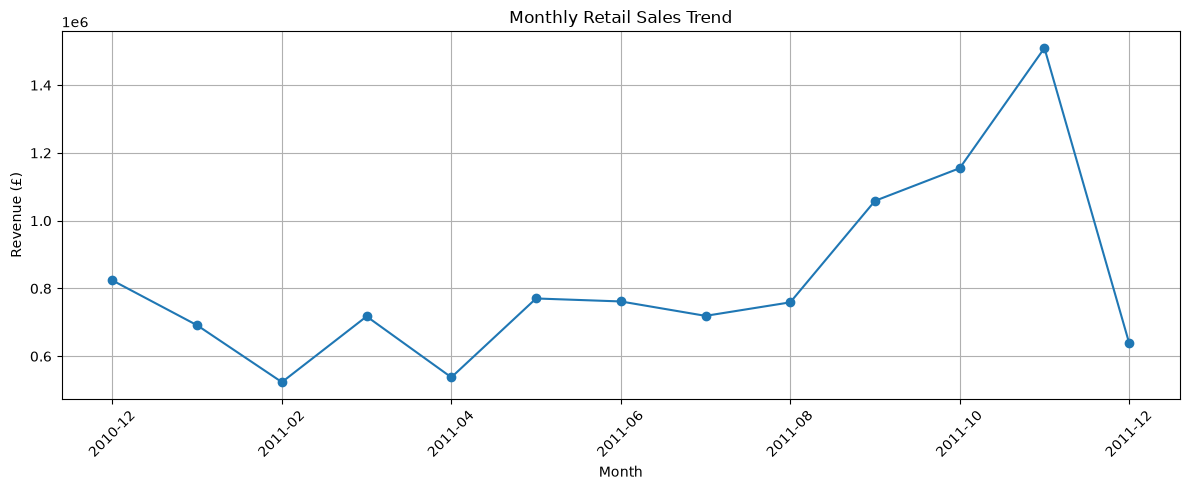

In [11]:
# Extract year and month
df["YearMonth"] = df["InvoiceDate"].dt.to_period("M")

# Calculate monthly revenue
monthly_sales = df.groupby("YearMonth")["TotalSales"].sum()

# Display results
display(monthly_sales.to_frame("Revenue (£)"))

# Plot monthly sales
monthly_sales.index = monthly_sales.index.astype(str)

monthly_sales.plot(
    kind="line",
    marker="o",
    figsize=(12, 5),
    title="Monthly Retail Sales Trend"
)

plt.xlabel("Month")
plt.ylabel("Revenue (£)")
plt.xticks(rotation=45)
plt.grid(True)
plt.tight_layout()
plt.show()

,Revenue (£)
Description,
DOTCOM POSTAGE,206248.77
REGENCY CAKESTAND 3 TIER,174484.74
"PAPER CRAFT , LITTLE BIRDIE",168469.60
WHITE HANGING HEART T-LIGHT HOLDER,106292.77
PARTY BUNTING,99504.33
JUMBO BAG RED RETROSPOT,94340.05
MEDIUM CERAMIC TOP STORAGE JAR,81700.92
POSTAGE,78119.88
Manual,78112.82


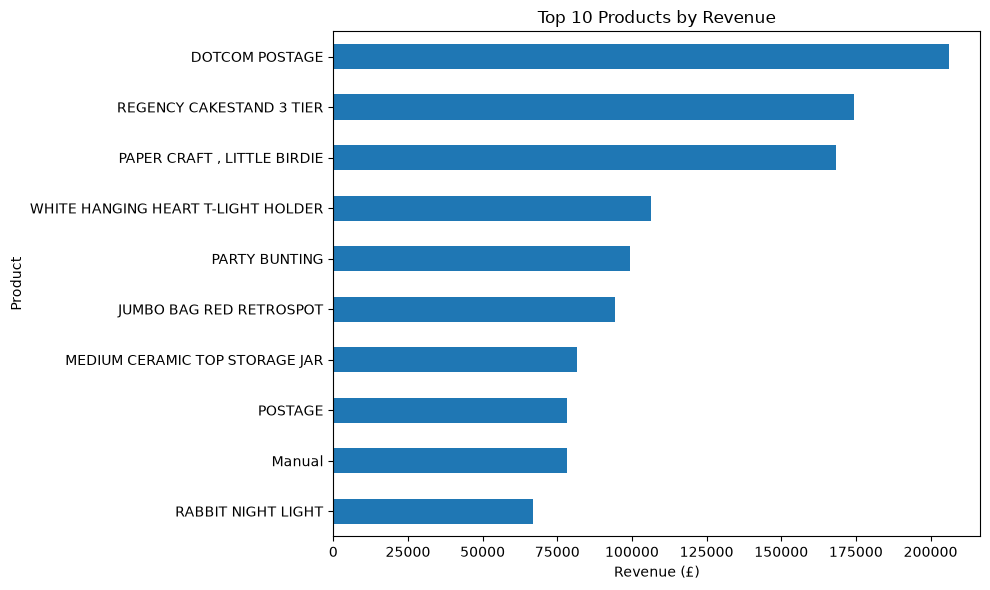

In [12]:
top_products = (
    df.groupby("Description")["TotalSales"]
    .sum()
    .nlargest(10)
)

display(top_products.to_frame("Revenue (£)"))

top_products.sort_values().plot(
    kind="barh",
    figsize=(10, 6),
    title="Top 10 Products by Revenue"
)

plt.xlabel("Revenue (£)")
plt.ylabel("Product")
plt.tight_layout()
plt.show()

,Revenue (£)
Customer ID,
14646.0,280206.02
18102.0,259657.30
17450.0,194550.79
16446.0,168472.50
14911.0,143825.06
12415.0,124914.53
14156.0,117379.63
17511.0,91062.38
16029.0,81024.84


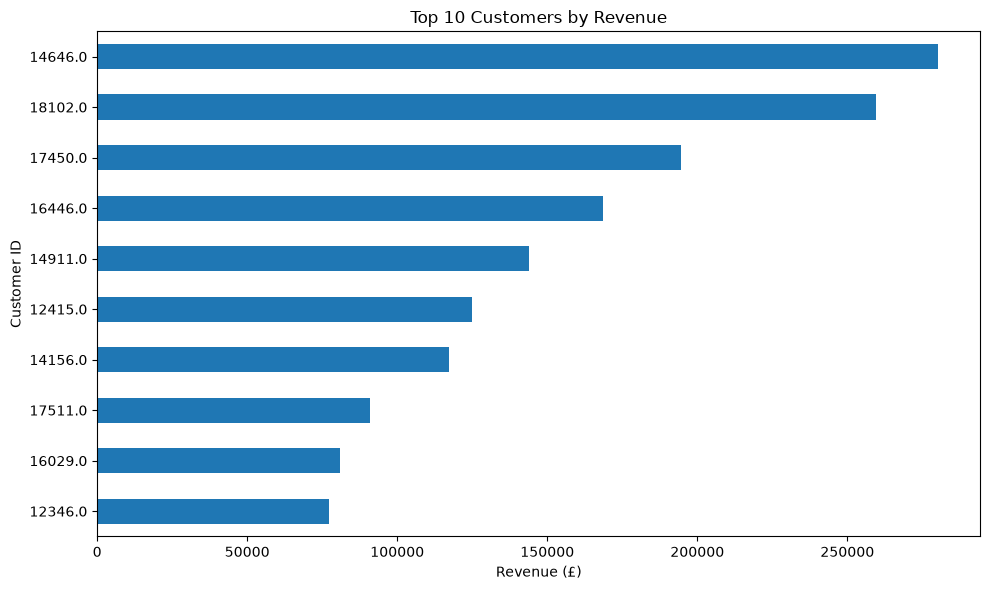

In [13]:
# Remove rows without Customer ID
customer_df = df.dropna(subset=["Customer ID"]).copy()

# Calculate revenue by customer
top_customers = (
    customer_df.groupby("Customer ID")["TotalSales"]
    .sum()
    .sort_values(ascending=False)
    .head(10)
)

display(top_customers.to_frame("Revenue (£)"))

top_customers.sort_values().plot(
    kind="barh",
    figsize=(10, 6),
    title="Top 10 Customers by Revenue"
)

plt.xlabel("Revenue (£)")
plt.ylabel("Customer ID")
plt.tight_layout()
plt.show()

,Revenue (£)
Country,
United Kingdom,9025222.084
Netherlands,285446.340
EIRE,283453.960
Germany,228867.140
France,209733.110
Australia,138521.310
Spain,61577.110
Switzerland,57089.900
Belgium,41196.340


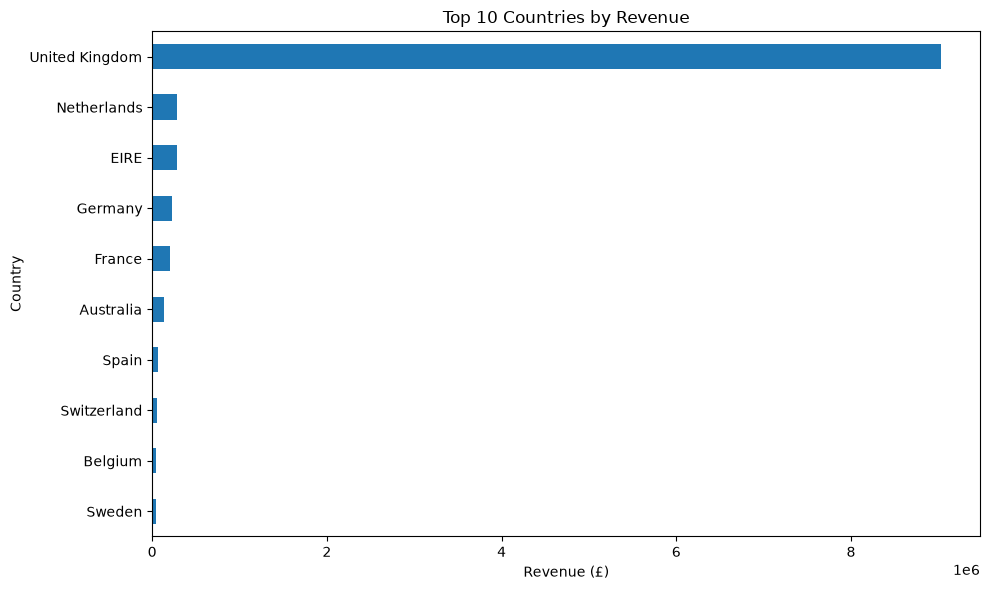

In [14]:
country_sales = (
    df.groupby("Country")["TotalSales"]
    .sum()
    .sort_values(ascending=False)
    .head(10)
)

display(country_sales.to_frame("Revenue (£)"))

country_sales.sort_values().plot(
    kind="barh",
    figsize=(10, 6),
    title="Top 10 Countries by Revenue"
)

plt.xlabel("Revenue (£)")
plt.ylabel("Country")
plt.tight_layout()
plt.show()

In [15]:
order_sales = df.groupby("Invoice")["TotalSales"].sum()

average_order_value = order_sales.mean()

print(f"Average Order Value: £{average_order_value:,.2f}")
print(f"Total Orders: {len(order_sales):,}")

Average Order Value: £534.40
Total Orders: 19,960


In [17]:
# Display key performance indicators
print("========== KEY PERFORMANCE INDICATORS ==========")
print(f"Total Revenue       : £{df['TotalSales'].sum():,.2f}")
print(f"Total Orders        : {df['Invoice'].nunique():,}")
print(f"Unique Customers    : {df['Customer ID'].nunique():,}")
print(f"Unique Products     : {df['StockCode'].nunique():,}")
print(
    f"Average Order Value : "
    f"£{df.groupby('Invoice')['TotalSales'].sum().mean():,.2f}"
)

========== KEY PERFORMANCE INDICATORS ==========
Total Revenue       : £10,666,702.54
Total Orders        : 19,960
Unique Customers    : 4,338
Unique Products     : 3,922
Average Order Value : £534.40
